# Pricing EDA: Product Selection for the United States and Canada

**SUMMARY**: This notebook checks currency consistency and selects products for pricing analysis using recent transaction activity and historical sales coverage. The results suggest that revenue is already recorded in a common currency across the US and Canada. We select Method 1 for both countries, retaining the 30 highest-scoring products within each country for subsequent pricing analysis.

## 1. Environment and Data Loading

### 1.1 Import Libraries and Locate Quarterly Files
Set `project_dir` to the project folder containing `raw data`. Run the notebook from the beginning so that all diagnostics use original financial values.

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display
import hashlib
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project root directory
project_dir = Path("/Users/AustinZhang/Desktop/Capstone")  # Change for your machine

cleaned_data_dir = project_dir / "cleaned data"
country_files = {
    "US": cleaned_data_dir / "US_valid_sales_all_transactions.csv",
    "CA": cleaned_data_dir / "CA_valid_sales_all_transactions.csv",
}

### 1.2 Combine Quarterly Transaction Files
Load all quarterly CSV files into one dataset. The source filename is retained for traceability, and every source row is preserved.

In [ ]:
country_data = {}

for country, file_path in country_files.items():
    data = pd.read_csv(file_path, low_memory=False, dtype={"product_id": "string"})

    for col in ["order_date", "return_date", "ship_date", "week_begin"]:
        if col in data.columns:
            data[col] = pd.to_datetime(data[col], errors="raise")

    if data.empty:
        raise ValueError(f"{file_path.name} contains no transactions.")
    if not data["country"].eq(country).all():
        raise ValueError(f"Unexpected country labels in {file_path.name}.")

    # Use shipped date if available, otherwise order date
    data["pricing_date"] = data["ship_date"].fillna(data["order_date"])
    if data["pricing_date"].isna().any():
        raise ValueError(f"Missing pricing dates in {file_path.name}.")

    # Calculate realized average selling price
    data["asp"] = data["revenue"] / data["order_units"]
    country_data[country] = data

    print(f"{country}: {len(data):,} rows, {len(data.columns)} columns")
    display(data.head())

pricing_eda = pd.concat(country_data.values(), ignore_index=True)

US: 2,717,497 rows, 38 columns


,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,...,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group,source_file,pricing_date,asp
0,2023-04-01,NaT,2023-04-02,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP08113696,TX,...,NaN,NaN,0-299,NaN,Sub-Family Radius Line,Product Family Romeo Iris,Product Group Golf Cobalt,synthesized_FY24Q1.csv,2023-04-02,49.99
1,2023-04-01,NaT,2023-04-02,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP08113696,NY,...,NaN,NaN,0-299,NaN,Sub-Family Radius Line,Product Family Romeo Iris,Product Group Golf Cobalt,synthesized_FY24Q1.csv,2023-04-02,22.00
2,2023-04-01,NaT,2023-04-02,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP08113696,NY,...,NaN,NaN,300-499,NaN,Sub-Family Radius Line,Product Family Romeo Iris,Product Group Golf Cobalt,synthesized_FY24Q1.csv,2023-04-02,414.73
3,2023-04-01,NaT,2023-04-02,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP08113696,FL,...,NaN,NaN,0-299,NaN,Sub-Family Radius Line,Product Family Romeo Iris,Product Group Golf Cobalt,synthesized_FY24Q1.csv,2023-04-02,69.99
4,2023-04-01,NaT,2023-04-01,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP08113696,TX,...,NaN,NaN,0-299,NaN,Sub-Family Radius Line,Product Family Romeo Iris,Product Group Golf Cobalt,synthesized_FY24Q1.csv,2023-04-01,211.75


CA: 498,263 rows, 38 columns


,order_date,return_date,ship_date,week_begin,month_fiscal,quarter_fiscal,document_type,document_category,customer_id,state,...,reason_of_return,reason_of_cancel,price_tier,rep_take_role,product_sub_family,product_family,product_family_group,source_file,pricing_date,asp
0,2023-04-01,NaT,2023-04-02,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP38967017,ON,...,NaN,NaN,0-299,NaN,Sub-Family Radius Line,Product Family Romeo Iris,Product Group Golf Cobalt,synthesized_FY24Q1.csv,2023-04-02,20.67
1,2023-04-01,NaT,2023-04-02,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP38967017,ON,...,NaN,NaN,0-299,NaN,Sub-Family Radius Line,Product Family Romeo Iris,Product Group Golf Cobalt,synthesized_FY24Q1.csv,2023-04-02,116.48
2,2023-04-01,NaT,2023-04-02,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP38967017,ON,...,NaN,NaN,0-299,NaN,Sub-Family Radius Line,Product Family Romeo Iris,Product Group Golf Cobalt,synthesized_FY24Q1.csv,2023-04-02,20.67
3,2023-04-01,NaT,2023-04-01,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP38967017,AB,...,NaN,NaN,0-299,NaN,Sub-Family Radius Line,Product Family Romeo Iris,Product Group Golf Cobalt,synthesized_FY24Q1.csv,2023-04-01,55.65
4,2023-04-01,NaT,2023-04-01,2023-03-27,April,FY24Q1,Invoice,Standard Invoice,DP38967017,BC,...,NaN,NaN,0-299,NaN,Sub-Family Radius Line,Product Family Romeo Iris,Product Group Golf Cobalt,synthesized_FY24Q1.csv,2023-04-01,20.67


### 2.2 Inspect Country Labels and Retain Original Amounts
Review the country labels before separating US and CA records. A country label alone does not establish the currency of a financial field, so no exchange-rate conversion is applied.

In [ ]:
# Currency remains unverified. Keep every original financial value unchanged.
print("Raw country labels:")
display(pricing_eda["country"].value_counts(dropna=False))

Raw country labels:


country
US    2717497
CA     498263
Name: count, dtype: int64

## 3. Pricing Scope and Recent Activity Window

Include shipped Enterprise transactions with positive units and revenue and a valid ship or order date. Calculate ASP as `revenue / order_units`. Use the same six-month window for US and CA, anchored to the latest eligible pricing date.

In [ ]:
# Define recent 6-month window
latest_date = pricing_eda["pricing_date"].max()
six_month_start = latest_date - pd.DateOffset(months=6)

recent = pricing_eda[pricing_eda["pricing_date"] >= six_month_start].copy()

print("Latest date:", latest_date)
print("Recent 6-month start:", six_month_start)
print("Rows in pricing scope:", len(pricing_eda))
print("Rows in recent 6-month scope:", len(recent))

Latest date: 2026-09-02 00:00:00
Recent 6-month start: 2026-03-02 00:00:00
Rows in pricing scope: 3215760
Rows in recent 6-month scope: 446995


## 4. Currency Consistency Diagnostics

Compare US and CA unit prices for matching products, months, price tiers, and sales channels. Also compare invoice-based and order-based unit prices to identify possible currency differences.
These comparisons provide evidence but do not confirm currency. Keep financial values unchanged until field-level currency definitions are verified.

In [6]:
# All diagnostics use the ORIGINAL amounts. No FX assumption or conversion.
def currency_diagnostics(pricing_data, min_rows=5, tolerance=0.05):
    data = pricing_data[pricing_data["country"].isin(["US", "CA"])].copy()
    data["month"] = data["pricing_date"].dt.to_period("M")
    data["unit_price_raw"] = data["revenue"] / data["order_units"]

    # Compare the same SKU in the same month, price tier and sales channel.
    # These diagnostics do not filter or modify the product-selection data.
    keys = ["product_id", "product_name", "month", "price_tier", "sales_channel"]
    valid = data.dropna(subset=["product_id", "product_name"])
    grouped = (
        valid.groupby(keys + ["country"], dropna=False)
        .agg(
            median_unit_price=("unit_price_raw", "median"),
            transaction_count=("unit_price_raw", "size"),
            units=("order_units", "sum"),
            revenue_raw=("revenue", "sum"),
        )
        .reset_index()
    )
    grouped["weighted_unit_price"] = grouped["revenue_raw"] / grouped["units"]
    us = grouped[grouped["country"].eq("US")].drop(columns="country")
    ca = grouped[grouped["country"].eq("CA")].drop(columns="country")
    pairs = us.merge(ca, on=keys, suffixes=("_US", "_CA"), validate="one_to_one")
    pairs["CA_over_US_median_price"] = (
        pairs["median_unit_price_CA"] / pairs["median_unit_price_US"]
    )
    pairs["CA_over_US_weighted_price"] = (
        pairs["weighted_unit_price_CA"] / pairs["weighted_unit_price_US"]
    )
    pairs["near_equal_5pct"] = (
        pairs["CA_over_US_median_price"].sub(1).abs().le(tolerance)
    )
    pairs["sufficient_rows"] = pairs["transaction_count_US"].ge(min_rows) & pairs[
        "transaction_count_CA"
    ].ge(min_rows)
    reliable = pairs[pairs["sufficient_rows"]]
    overview = pd.DataFrame(
        [
            {
                "matched_groups": len(pairs),
                "groups_with_min_rows_each_country": len(reliable),
                "min_rows_each_country": min_rows,
                "relative_tolerance": tolerance,
                "median_CA_over_US_price": reliable["CA_over_US_median_price"].median(),
                "ratio_p25": reliable["CA_over_US_median_price"].quantile(0.25),
                "ratio_p75": reliable["CA_over_US_median_price"].quantile(0.75),
                "share_near_equal": reliable["near_equal_5pct"].mean(),
            }
        ]
    )
    monthly = (
        reliable.groupby("month")
        .agg(
            matched_groups=("CA_over_US_median_price", "size"),
            median_CA_over_US_price=("CA_over_US_median_price", "median"),
            share_near_equal=("near_equal_5pct", "mean"),
        )
        .reset_index()
    )
    # The field name alone does not establish which currency revenue uses.
    # Unit-price comparison also accounts for differing invoice/order quantities.
    invoice = data[
        data["invoice_quantity"].gt(0) & data["invoice_revenue_country_currency"].gt(0)
    ].copy()
    invoice["invoice_unit_price_raw"] = (
        invoice["invoice_revenue_country_currency"] / invoice["invoice_quantity"]
    )
    invoice["invoice_unit_over_order_unit"] = (
        invoice["invoice_unit_price_raw"] / invoice["unit_price_raw"]
    )
    invoice["invoice_total_over_revenue"] = (
        invoice["invoice_revenue_country_currency"] / invoice["revenue"]
    )
    invoice_summary = (
        invoice.groupby("country")
        .agg(
            usable_invoice_rows=("invoice_unit_over_order_unit", "size"),
            median_invoice_unit_over_order_unit=(
                "invoice_unit_over_order_unit",
                "median",
            ),
            ratio_p25=("invoice_unit_over_order_unit", lambda x: x.quantile(0.25)),
            ratio_p75=("invoice_unit_over_order_unit", lambda x: x.quantile(0.75)),
            median_invoice_total_over_revenue=("invoice_total_over_revenue", "median"),
        )
        .reindex(["US", "CA"])
    )
    scope_counts = data.groupby("country").size().reindex(["US", "CA"], fill_value=0)
    invoice_summary["pricing_rows"] = scope_counts
    invoice_summary["usable_invoice_rows"] = (
        invoice_summary["usable_invoice_rows"].fillna(0).astype(int)
    )
    invoice_summary["invoice_usable_share"] = invoice_summary[
        "usable_invoice_rows"
    ] / scope_counts.replace(0, np.nan)
    return {
        "overview": overview,
        "matched_prices": pairs,
        "monthly": monthly,
        "invoice_summary": invoice_summary.reset_index(),
    }


currency_checks = currency_diagnostics(pricing_eda)
for name in ["overview", "monthly", "invoice_summary"]:
    print(name)
    display(currency_checks[name])
display(
    currency_checks["matched_prices"]
    .sort_values(["sufficient_rows", "transaction_count_CA"], ascending=False)
    .head(30)
)

overview


,matched_groups,groups_with_min_rows_each_country,min_rows_each_country,relative_tolerance,median_CA_over_US_price,ratio_p25,ratio_p75,share_near_equal
0,42391,16703,5,0.05,0.98892,0.938326,1.01943,0.563911


monthly


,month,matched_groups,median_CA_over_US_price,share_near_equal
0,2023-04,347,0.994167,0.573487
1,2023-05,415,0.999213,0.571084
2,2023-06,410,1.009952,0.609756
3,2023-07,356,1.005354,0.637640
4,2023-08,463,1.000000,0.600432
5,2023-09,442,0.993268,0.615385
6,2023-10,392,0.986760,0.584184
7,2023-11,587,0.991439,0.604770
8,2023-12,463,1.000000,0.591793
9,2024-01,401,1.001216,0.588529


invoice_summary


,country,usable_invoice_rows,median_invoice_unit_over_order_unit,ratio_p25,ratio_p75,median_invoice_total_over_revenue,pricing_rows,invoice_usable_share
0,US,2713754,1.000000,1.000000,1.000000,1.000000,2717497,0.998623
1,CA,498066,1.370203,1.354274,1.391595,1.370203,498263,0.999605


,product_id,product_name,month,price_tier,sales_channel,median_unit_price_US,transaction_count_US,units_US,revenue_raw_US,weighted_unit_price_US,median_unit_price_CA,transaction_count_CA,units_CA,revenue_raw_CA,weighted_unit_price_CA,CA_over_US_median_price,CA_over_US_weighted_price,near_equal_5pct,sufficient_rows
39459,97U5A3MX99,64V0N1L148 FALCON SKY,2023-11,500-699,Direct,599.000,2351,2841.0,1716375.72,604.144921,614.150000,662,823.0,505836.15,614.624727,1.025292,1.017347,True,True
10599,27WH3132DN,YA QSA-I ROSE 200V ELEMENT,2026-03,0-299,Direct,138.120,2532,4208.0,565662.47,134.425492,138.950000,575,1136.0,160669.14,141.434102,1.006009,1.052138,True,True
31892,77T98518VL,MOMENTUM IMPACTROP ZNJ-E FLOW N0,2023-11,0-299,Direct,159.990,2252,3213.0,498805.60,155.246063,158.584000,572,914.0,142707.57,156.135197,0.991212,1.005727,True,True
10581,27WH3132DN,YA QSA-I ROSE 200V ELEMENT,2024-11,0-299,Direct,159.990,2206,3458.0,560371.34,162.050706,155.770000,521,861.0,133061.44,154.542904,0.973623,0.953670,True,True
10598,27WH3132DN,YA QSA-I ROSE 200V ELEMENT,2026-02,0-299,Direct,130.670,2423,4083.0,526390.52,128.922488,136.357500,500,862.0,118869.85,137.900058,1.043526,1.069635,True,True
37271,8PK1H20941,STATION ELEMENT VITALKZZUZXQT SXE-TMWQ,2024-02,0-299,Direct,22.000,2363,2363.0,51321.44,21.718764,20.760000,474,474.0,9486.21,20.013101,0.943636,0.921466,False,True
33414,7LL8J24163,CATALYST 7E INSIGHT CIRCUIT UNIT,2024-12,0-299,Direct,0.010,1353,2557.0,1153.57,0.451142,0.010000,464,774.0,80.24,0.103669,1.000000,0.229793,True,True
37268,8PK1H20941,STATION ELEMENT VITALKZZUZXQT SXE-TMWQ,2023-11,0-299,Direct,22.000,2414,2414.0,52602.41,21.790559,20.400000,459,459.0,9244.88,20.141351,0.927273,0.924315,False,True
10600,27WH3132DN,YA QSA-I ROSE 200V ELEMENT,2026-04,0-299,Direct,131.180,2113,3762.0,517241.06,137.490978,140.370000,443,823.0,118042.38,143.429380,1.070056,1.043191,False,True
31898,77T98518VL,MOMENTUM IMPACTROP ZNJ-E FLOW N0,2024-02,0-299,Direct,152.240,1805,2794.0,415192.85,148.601593,153.925000,442,771.0,115512.93,149.822218,1.011068,1.008214,True,True


## 5. Core Product Scope

### 5.1 Review Recent Product-Type Activity
Summarize recent transaction counts, revenue, units, and product diversity by product type before applying the core-product filter.

In [7]:
# Review product types before filtering

product_type_summary = (
    recent.groupby("product_type", dropna=False)
    .agg(
        transaction_count=("product_type", "size"),
        revenue=("revenue", "sum"),
        order_units=("order_units", "sum"),
        product_count=("product_name", "nunique"),
        family_count=("product_family", "nunique"),
    )
    .reset_index()
)

product_type_summary["weighted_asp"] = (
    product_type_summary["revenue"] / product_type_summary["order_units"]
)

product_type_summary = product_type_summary.sort_values(
    "transaction_count", ascending=False
)

display(product_type_summary)

,product_type,transaction_count,revenue,order_units,product_count,family_count,weighted_asp
5,Services,146973,2.253969e+07,213497.0,645,2,105.573802
1,Notebook,108567,2.334058e+08,162271.0,243,4,1438.370275
2,Options,102723,1.557423e+07,155494.0,428,2,100.159709
8,Workstations,34491,1.190792e+08,47344.0,126,1,2515.190667
7,Visuals,20992,8.700346e+06,45304.0,47,1,192.043653
0,Desktop,20367,3.373059e+07,28545.0,126,2,1181.663762
6,Shipping,11530,5.105240e+05,11530.0,3,1,44.277886
4,Servers,997,3.099529e+06,1132.0,77,2,2738.099602
9,NaN,187,2.039080e+03,203.0,1,0,10.044729
3,Phones,168,4.696028e+04,179.0,8,1,262.347933


In [ ]:
# Section: Filter Core Product Types

core_product_types = ["Notebook", "Workstations", "Desktop", "Visuals", "Servers"]

pricing_eda_core = pricing_eda[
    pricing_eda["product_type"].isin(core_product_types)
].copy()

recent = recent[recent["product_type"].isin(core_product_types)].copy()

print("Rows in pricing scope:", len(pricing_eda))
print("Rows in core pricing scope:", len(pricing_eda_core))
print("Rows in recent 6-month scope:", len(recent))
print("Rows in recent core scope:", len(recent))

country_core_data = {
    country: pricing_eda_core[pricing_eda_core["country"].eq(country)].copy()
    for country in country_files
}
country_recent_data = {
    country: recent[recent["country"].eq(country)].copy() for country in country_files
}

Rows in pricing scope: 3215760
Rows in core pricing scope: 1306181
Rows in recent 6-month scope: 185414
Rows in recent core scope: 185414


## 6. Country-Level Product Selection

Products are evaluated separately for the US and Canada using formula `0.5*coverage + 0.5*transaction`, an equally weighted score combining recent six-month transaction-count percentiles and historical coverage-rate percentiles. Coverage measures the share of observed months in which a product had transactions.
- Method 1: Select the 30 highest-scoring products within each country.
- Method 2: Identify the five families with the most recent transactions, then select the six highest-scoring products from each family.

Both methods are applied to each country, and the selected products are compared using revenue and order units.

In [ ]:
def select_country_products(core_data, recent_data, country):
    pricing_eda_core = core_data[core_data["country"].eq(country)].copy()
    recent = recent_data[recent_data["country"].eq(country)].copy()
    # Section: Historical Coverage Metrics

    pricing_eda_core["month"] = pricing_eda_core["pricing_date"].dt.to_period("M")
    total_months = pricing_eda_core["month"].nunique()

    product_coverage = (
        pricing_eda_core.groupby("product_name", dropna=False)
        .agg(
            active_months=("month", "nunique"),
            full_period_transaction_count=("product_name", "size"),
            full_period_revenue=("revenue", "sum"),
            full_period_units=("order_units", "sum"),
            latest_transaction_date=("pricing_date", "max"),
        )
        .reset_index()
    )

    product_coverage["coverage_rate"] = product_coverage["active_months"] / total_months

    # Method 1 - Product-level selection using recent activity and historical coverage

    method1_candidates = (
        recent.groupby(["product_name", "product_family", "product_type"], dropna=False)
        .agg(
            transaction_count=("product_name", "size"),
            revenue=("revenue", "sum"),
            order_units=("order_units", "sum"),
            margin=("margin", "sum"),
            price_tier_count=("price_tier", "nunique"),
        )
        .reset_index()
    )

    method1_candidates = method1_candidates.merge(
        product_coverage, on="product_name", how="left"
    )

    method1_candidates["selection_score"] = (
        method1_candidates["transaction_count"].rank(pct=True) * 0.5
        + method1_candidates["coverage_rate"].rank(pct=True) * 0.5
    )

    method1_candidates["weighted_asp"] = (
        method1_candidates["revenue"] / method1_candidates["order_units"]
    )

    method1_candidates["margin_rate"] = (
        method1_candidates["margin"] / method1_candidates["revenue"]
    )

    method1_top30_products = (
        method1_candidates.sort_values("selection_score", ascending=False)
        .head(30)
        .reset_index(drop=True)
    )

    # Check product families represented in Method 1

    method1_family_summary = (
        method1_top30_products.groupby("product_family", dropna=False)
        .agg(
            selected_products=("product_name", "nunique"),
            total_transactions=("transaction_count", "sum"),
            total_revenue=("revenue", "sum"),
            total_units=("order_units", "sum"),
        )
        .reset_index()
        .sort_values("total_transactions", ascending=False)
    )

    # Method 2 - Select Top 5 Families

    family_recent = (
        recent.groupby("product_family", dropna=False)
        .agg(
            transaction_count=("product_family", "size"),
            revenue=("revenue", "sum"),
            order_units=("order_units", "sum"),
            margin=("margin", "sum"),
        )
        .reset_index()
    )

    family_recent["weighted_asp"] = (
        family_recent["revenue"] / family_recent["order_units"]
    )
    family_recent["margin_rate"] = family_recent["margin"] / family_recent["revenue"]

    method2_top5_families = (
        family_recent.sort_values("transaction_count", ascending=False)
        .head(5)
        .reset_index(drop=True)
    )

    top5_family_names = method2_top5_families["product_family"].tolist()

    # Method 2 - Select Top 6 Products per Top Family using recent activity and historical coverage

    product_recent_all = (
        recent.groupby(["product_family", "product_name", "product_type"], dropna=False)
        .agg(
            transaction_count=("product_name", "size"),
            revenue=("revenue", "sum"),
            order_units=("order_units", "sum"),
            margin=("margin", "sum"),
            price_tier_count=("price_tier", "nunique"),
        )
        .reset_index()
    )

    product_recent_all = product_recent_all.merge(
        product_coverage, on="product_name", how="left"
    )

    product_recent_all["selection_score"] = (
        product_recent_all["transaction_count"].rank(pct=True) * 0.5
        + product_recent_all["coverage_rate"].rank(pct=True) * 0.5
    )

    product_recent_all["weighted_asp"] = (
        product_recent_all["revenue"] / product_recent_all["order_units"]
    )

    product_recent_all["margin_rate"] = (
        product_recent_all["margin"] / product_recent_all["revenue"]
    )

    method2_top6_each_family = (
        product_recent_all[product_recent_all["product_family"].isin(top5_family_names)]
        .sort_values(["product_family", "selection_score"], ascending=[True, False])
        .groupby("product_family", dropna=False)
        .head(6)
        .reset_index(drop=True)
    )
    return {
        "product_coverage": product_coverage,
        "total_months": total_months,
        "method1_candidates": method1_candidates,
        "method1_top30_products": method1_top30_products,
        "method1_family_summary": method1_family_summary,
        "method2_top5_families": method2_top5_families,
        "method2_top6_each_family": method2_top6_each_family,
    }


country_results = {
    country: select_country_products(
        country_core_data[country], country_recent_data[country], country
    )
    for country in ["US", "CA"]
}
us_top30 = country_results["US"]["method1_top30_products"]
canada_top30 = country_results["CA"]["method1_top30_products"]
for country, result in country_results.items():
    print(country, "historical observed months:", result["total_months"])
    print("Method 1 selected rows:", len(result["method1_top30_products"]))
    display(result["method1_top30_products"])
    print("Method 2 selected rows:", len(result["method2_top6_each_family"]))
    display(result["method2_top6_each_family"])

US historical observed months: 42
Method 1 selected rows: 30


,product_name,product_family,product_type,transaction_count,revenue,order_units,margin,price_tier_count,active_months,full_period_transaction_count,full_period_revenue,full_period_units,latest_transaction_date,coverage_rate,selection_score,weighted_asp,margin_rate
0,LI ON W78 RAY Z8 H7 35N 710K 65G,Product Family Knight Thrive,Notebook,931,1340282.08,1482.0,1.559525e+05,6,27,4471,5323710.75,7174.0,2026-08-14,0.642857,0.954248,904.373873,0.116358
1,SOLSTICE FRONTIER P0 HARBOR K85 SKY 37KU,Product Family Frame Road,Notebook,1748,4516147.73,2298.0,1.223940e+06,7,20,5611,14419330.18,7030.0,2026-06-24,0.476190,0.940768,1965.251406,0.271014
2,A77U-61(K04687BO9)85.0MNCO JGPZQCG-ERDK,Product Family Quest Lunar,Visuals,573,174409.69,982.0,6.436062e+04,2,38,2826,808639.86,4551.0,2026-08-28,0.904762,0.939542,177.606609,0.369020
3,CATALYST FRONTIER E8 JULIET D53 SUN 39RD,Product Family Frame Road,Notebook,1646,3586977.32,2111.0,9.204863e+05,7,20,7600,17394146.94,8444.0,2026-06-12,0.476190,0.938317,1699.183951,0.256619
4,ST PL SOLSTICE O9-61 M7 K7 09D 168C 62M,Product Family Frame Road,Notebook,1349,3179172.99,1775.0,8.306186e+05,7,20,2633,5717789.64,3205.0,2026-08-27,0.476190,0.934232,1791.083375,0.261269
5,EL UN SOLSTICE U0-28 R3 Z5 42U 3W 71Y,Product Family Frame Road,Notebook,1294,2736748.82,1829.0,6.040564e+05,9,20,2773,5577415.85,3638.0,2026-08-14,0.476190,0.931781,1496.308814,0.220720
6,CATALYST SENTINEL C1 FUSION N12 ARC 08CW,Product Family Frame Road,Notebook,1750,5463562.44,2449.0,2.619893e+06,6,17,4793,13868090.92,6211.0,2026-08-28,0.404762,0.930147,2230.936072,0.479521
7,INTEGRAL SOLSTICE J9 JULIET Y50 SKY 56XN,Product Family Frame Road,Notebook,2682,7576480.67,3985.0,1.630533e+06,9,15,5234,14312351.43,7601.0,2026-08-27,0.357143,0.923203,1901.249854,0.215210
8,13QB164REZ STREAM RAY,Product Family Frame Road,Notebook,2512,6444744.00,3887.0,1.910216e+06,8,15,4365,10306603.37,6429.0,2026-08-03,0.357143,0.922386,1658.025212,0.296399
9,LI HO SOLSTICE G1-79 V9 P1 55M 8T 59T,Product Family Frame Road,Notebook,1009,2221313.60,1399.0,4.350052e+05,8,19,2380,4895044.29,3070.0,2026-07-29,0.452381,0.920752,1587.786705,0.195832


Method 2 selected rows: 30


,product_family,product_name,product_type,transaction_count,revenue,order_units,margin,price_tier_count,active_months,full_period_transaction_count,full_period_revenue,full_period_units,latest_transaction_date,coverage_rate,selection_score,weighted_asp,margin_rate
0,Product Family Frame Road,SOLSTICE FRONTIER P0 HARBOR K85 SKY 37KU,Notebook,1748,4516147.73,2298.0,1.223940e+06,7,20,5611,14419330.18,7030.0,2026-06-24,0.476190,0.940768,1965.251406,0.271014
1,Product Family Frame Road,CATALYST FRONTIER E8 JULIET D53 SUN 39RD,Notebook,1646,3586977.32,2111.0,9.204863e+05,7,20,7600,17394146.94,8444.0,2026-06-12,0.476190,0.938317,1699.183951,0.256619
2,Product Family Frame Road,ST PL SOLSTICE O9-61 M7 K7 09D 168C 62M,Notebook,1349,3179172.99,1775.0,8.306186e+05,7,20,2633,5717789.64,3205.0,2026-08-27,0.476190,0.934232,1791.083375,0.261269
3,Product Family Frame Road,EL UN SOLSTICE U0-28 R3 Z5 42U 3W 71Y,Notebook,1294,2736748.82,1829.0,6.040564e+05,9,20,2773,5577415.85,3638.0,2026-08-14,0.476190,0.931781,1496.308814,0.220720
4,Product Family Frame Road,CATALYST SENTINEL C1 FUSION N12 ARC 08CW,Notebook,1750,5463562.44,2449.0,2.619893e+06,6,17,4793,13868090.92,6211.0,2026-08-28,0.404762,0.930147,2230.936072,0.479521
5,Product Family Frame Road,INTEGRAL SOLSTICE J9 JULIET Y50 SKY 56XN,Notebook,2682,7576480.67,3985.0,1.630533e+06,9,15,5234,14312351.43,7601.0,2026-08-27,0.357143,0.923203,1901.249854,0.215210
6,Product Family Knight Thrive,LI ON W78 RAY Z8 H7 35N 710K 65G,Notebook,931,1340282.08,1482.0,1.559525e+05,6,27,4471,5323710.75,7174.0,2026-08-14,0.642857,0.954248,904.373873,0.116358
7,Product Family Knight Thrive,U04 W9,Notebook,2955,5140260.39,5340.0,6.965596e+05,7,14,4878,7824730.04,8370.0,2026-08-29,0.333333,0.899510,962.595579,0.135511
8,Product Family Knight Thrive,K77 E3,Notebook,1992,3283946.63,3260.0,5.224134e+05,6,14,3886,5787789.53,6283.0,2026-08-29,0.333333,0.897059,1007.345592,0.159081
9,Product Family Knight Thrive,H07 ARC P1,Notebook,1787,2959859.56,2902.0,3.550967e+05,7,14,2256,3589631.05,3688.0,2026-08-29,0.333333,0.893791,1019.937822,0.119971


CA historical observed months: 42
Method 1 selected rows: 30


,product_name,product_family,product_type,transaction_count,revenue,order_units,margin,price_tier_count,active_months,full_period_transaction_count,full_period_revenue,full_period_units,latest_transaction_date,coverage_rate,selection_score,weighted_asp,margin_rate
0,LI ON W78 RAY Z8 H7 35N 710K 65G,Product Family Knight Thrive,Notebook,424,523448.63,608.0,46323.749486,5,25,997,1101221.28,1413.0,2026-08-22,0.595238,0.988683,860.935247,0.088497
1,SOLSTICE FRONTIER P0 HARBOR K85 SKY 37KU,Product Family Frame Road,Notebook,226,562541.05,253.0,233583.667651,3,22,651,1503742.46,693.0,2026-08-10,0.523810,0.958848,2223.482411,0.415230
2,K77 E3,Product Family Knight Thrive,Notebook,406,593762.00,601.0,134431.398992,5,14,615,852482.98,906.0,2026-08-29,0.333333,0.940329,987.956739,0.226406
3,WH BR V75I RAY K2 SQ_F4 61G 3K 19R,Product Family Solar Peak,Workstations,306,799305.90,444.0,197735.459028,6,14,609,1232152.60,821.0,2026-08-27,0.333333,0.933128,1800.238514,0.247384
4,13QB164REZ STREAM RAY,Product Family Frame Road,Notebook,413,955741.33,610.0,294332.302214,7,13,769,1665346.83,1097.0,2026-08-28,0.309524,0.931584,1566.789066,0.307962
5,A77U-61(K04687BO9)85.0MNCO JGPZQCG-ERDK,Product Family Quest Lunar,Visuals,109,39946.98,229.0,13810.939929,2,37,681,212070.65,1261.0,2026-08-26,0.880952,0.930041,174.440961,0.345732
6,INTEGRAL SOLSTICE J9 JULIET Y50 SKY 56XN,Product Family Frame Road,Notebook,409,924703.21,517.0,208783.418416,7,13,750,1734737.27,977.0,2026-08-27,0.309524,0.929527,1788.594217,0.225784
7,NOVEMBER CATALYST T9 GALAXY L77 RAY 48ER,Product Family Frame Road,Notebook,265,551901.29,305.0,173498.619477,5,14,434,933102.41,502.0,2026-07-20,0.333333,0.927984,1809.512426,0.314365
8,EMBERFCKGPT X82,Product Family Quest Lunar,Visuals,112,24849.87,156.0,7646.500100,1,27,1919,334233.06,2427.0,2026-04-28,0.642857,0.926955,159.294038,0.307708
9,20LRI66892 QUEBEC SKY,Product Family Frame Road,Notebook,377,936316.59,588.0,293349.825513,6,13,635,1396609.19,942.0,2026-08-28,0.309524,0.926440,1592.375153,0.313302


Method 2 selected rows: 30


,product_family,product_name,product_type,transaction_count,revenue,order_units,margin,price_tier_count,active_months,full_period_transaction_count,full_period_revenue,full_period_units,latest_transaction_date,coverage_rate,selection_score,weighted_asp,margin_rate
0,Product Family Frame Road,SOLSTICE FRONTIER P0 HARBOR K85 SKY 37KU,Notebook,226,562541.05,253.0,233583.667651,3,22,651,1503742.46,693.0,2026-08-10,0.523810,0.958848,2223.482411,0.415230
1,Product Family Frame Road,13QB164REZ STREAM RAY,Notebook,413,955741.33,610.0,294332.302214,7,13,769,1665346.83,1097.0,2026-08-28,0.309524,0.931584,1566.789066,0.307962
2,Product Family Frame Road,INTEGRAL SOLSTICE J9 JULIET Y50 SKY 56XN,Notebook,409,924703.21,517.0,208783.418416,7,13,750,1734737.27,977.0,2026-08-27,0.309524,0.929527,1788.594217,0.225784
3,Product Family Frame Road,NOVEMBER CATALYST T9 GALAXY L77 RAY 48ER,Notebook,265,551901.29,305.0,173498.619477,5,14,434,933102.41,502.0,2026-07-20,0.333333,0.927984,1809.512426,0.314365
4,Product Family Frame Road,20LRI66892 QUEBEC SKY,Notebook,377,936316.59,588.0,293349.825513,6,13,635,1396609.19,942.0,2026-08-28,0.309524,0.926440,1592.375153,0.313302
5,Product Family Frame Road,CATALYST FRONTIER E8 JULIET D53 SUN 39RD,Notebook,143,285974.08,164.0,87240.329040,6,20,556,1274632.43,620.0,2026-06-30,0.476190,0.926440,1743.744390,0.305064
6,Product Family Knight Thrive,LI ON W78 RAY Z8 H7 35N 710K 65G,Notebook,424,523448.63,608.0,46323.749486,5,25,997,1101221.28,1413.0,2026-08-22,0.595238,0.988683,860.935247,0.088497
7,Product Family Knight Thrive,K77 E3,Notebook,406,593762.00,601.0,134431.398992,5,14,615,852482.98,906.0,2026-08-29,0.333333,0.940329,987.956739,0.226406
8,Product Family Knight Thrive,C75 C9,Notebook,503,714334.38,760.0,111236.410280,5,12,674,899737.13,991.0,2026-08-29,0.285714,0.911008,939.913658,0.155720
9,Product Family Knight Thrive,U04 W9,Notebook,442,793082.75,747.0,155114.041188,6,12,632,1043186.44,1019.0,2026-08-29,0.285714,0.909979,1061.690428,0.195584


## 7. Compare Selection Methods Within Each Country

### 7.1 Transaction-Count Charts
Inspect the recent transaction activity represented by each selected product and its product family.

In [21]:
def plot_transaction_count_bars(summary_df, method_title, family_palette, family_order):
    plot_df = summary_df.copy()
    plot_df = plot_df.sort_values("transaction_count", ascending=True)

    plt.figure(figsize=(10, 8))

    ax = sns.barplot(
        data=plot_df,
        y="product_name",
        x="transaction_count",
        hue="product_family",
        hue_order=family_order,
        palette=family_palette,
        dodge=False,
    )

    ax.set_title(f"{method_title}: Recent Transaction Count")
    ax.set_xlabel("Transaction Count")
    ax.set_ylabel("Product")
    ax.legend(title="Product Family", bbox_to_anchor=(1.05, 1), loc="upper left")

    plt.tight_layout()
    plt.show()

### 7.2 Price-Tier Distribution
Summarize transaction counts across price tiers for each selected product. The heatmap describes the distribution of transactions rather than a currency assignment.

In [11]:
# Helper function: price tier heatmap by product
def plot_price_tier_heatmap(selected_recent_df, method_title):
    tier_matrix = (
        selected_recent_df.groupby(["product_name", "price_tier"], dropna=False)
        .size()
        .reset_index(name="transaction_count")
        .pivot(index="product_name", columns="price_tier", values="transaction_count")
        .fillna(0)
    )

    product_order = tier_matrix.sum(axis=1).sort_values(ascending=False).index
    tier_matrix = tier_matrix.loc[product_order]

    plt.figure(figsize=(14, 9))

    sns.heatmap(
        tier_matrix,
        cmap="Blues",
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Transaction Count"},
    )

    plt.title(f"{method_title}: Product Distribution Across Price Tiers")
    plt.xlabel("Price Tier")
    plt.ylabel("Product")
    plt.tight_layout()
    plt.show()

### 7.3 Historical Sales Coverage by Four-Month Period
Summarize selected-product units in four-month periods anchored to the earliest selected-product transaction. Heatmap values are capped at 2,000 units for readability; the underlying summaries retain their actual values.

In [12]:
# Helper function: check selected product sales coverage by 4-month period


def check_product_period_coverage(
    data, selected_products, date_col="pricing_date", period_months=4
):
    temp = data[data["product_name"].isin(selected_products)].copy()

    # Create 4-month period index from the earliest date in the dataset
    start_date = temp[date_col].min()
    temp["months_since_start"] = (temp[date_col].dt.year - start_date.year) * 12 + (
        temp[date_col].dt.month - start_date.month
    )

    temp["period_index"] = temp["months_since_start"] // period_months

    temp["period_start"] = start_date + temp["period_index"].apply(
        lambda x: pd.DateOffset(months=int(x * period_months))
    )

    period_summary = (
        temp.groupby(["product_name", "period_index", "period_start"], dropna=False)
        .agg(
            transaction_count=("product_name", "size"),
            order_units=("order_units", "sum"),
            revenue=("revenue", "sum"),
        )
        .reset_index()
    )

    return period_summary


def plot_period_units_heatmap(period_summary, method_title, cap=2000):
    units_matrix = period_summary.pivot(
        index="product_name", columns="period_start", values="order_units"
    ).fillna(0)

    product_order = units_matrix.sum(axis=1).sort_values(ascending=False).index
    units_matrix = units_matrix.loc[product_order]

    # Cap values so anything above cap has the same color
    units_matrix_capped = units_matrix.clip(upper=cap)

    # Format x-axis labels as YYYY-MM-DD
    date_labels = pd.to_datetime(units_matrix.columns).strftime("%Y-%m-%d")

    plt.figure(figsize=(14, 9))

    sns.heatmap(
        units_matrix_capped,
        cmap="Blues",
        linewidths=0.5,
        linecolor="white",
        vmin=0,
        vmax=cap,
        xticklabels=date_labels,
        cbar_kws={"label": f"Order Units (capped at {cap})"},
    )

    plt.title(f"{method_title}: Order Units by 4-Month Period")
    plt.xlabel("4-Month Period Start")
    plt.ylabel("Product")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### 7.4 Method 1 and Method 2 Comparison Results
For each country, display the family summaries, revenue and unit charts, transaction-count charts, price-tier heatmaps, and historical coverage summaries. Every chart uses transactions from that country only. Compare the two methods within each country when assessing the scale and coverage of the selected products.

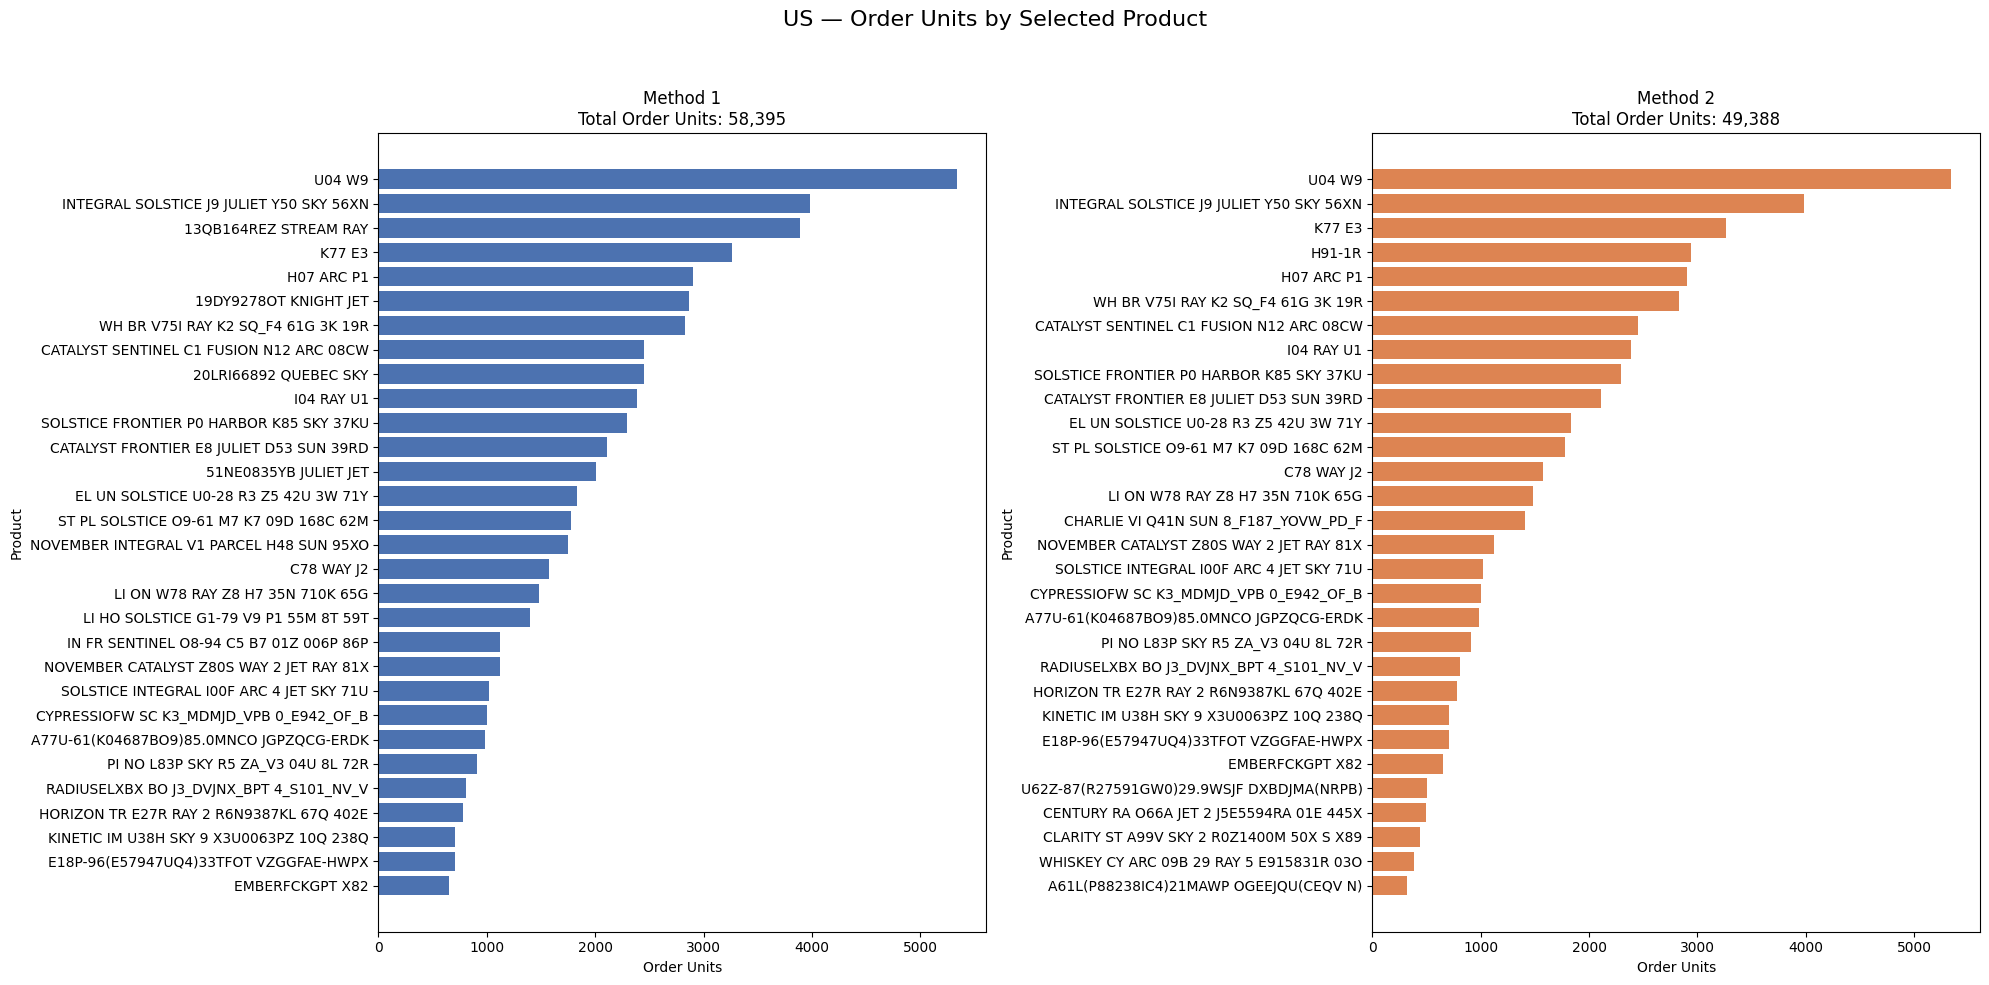

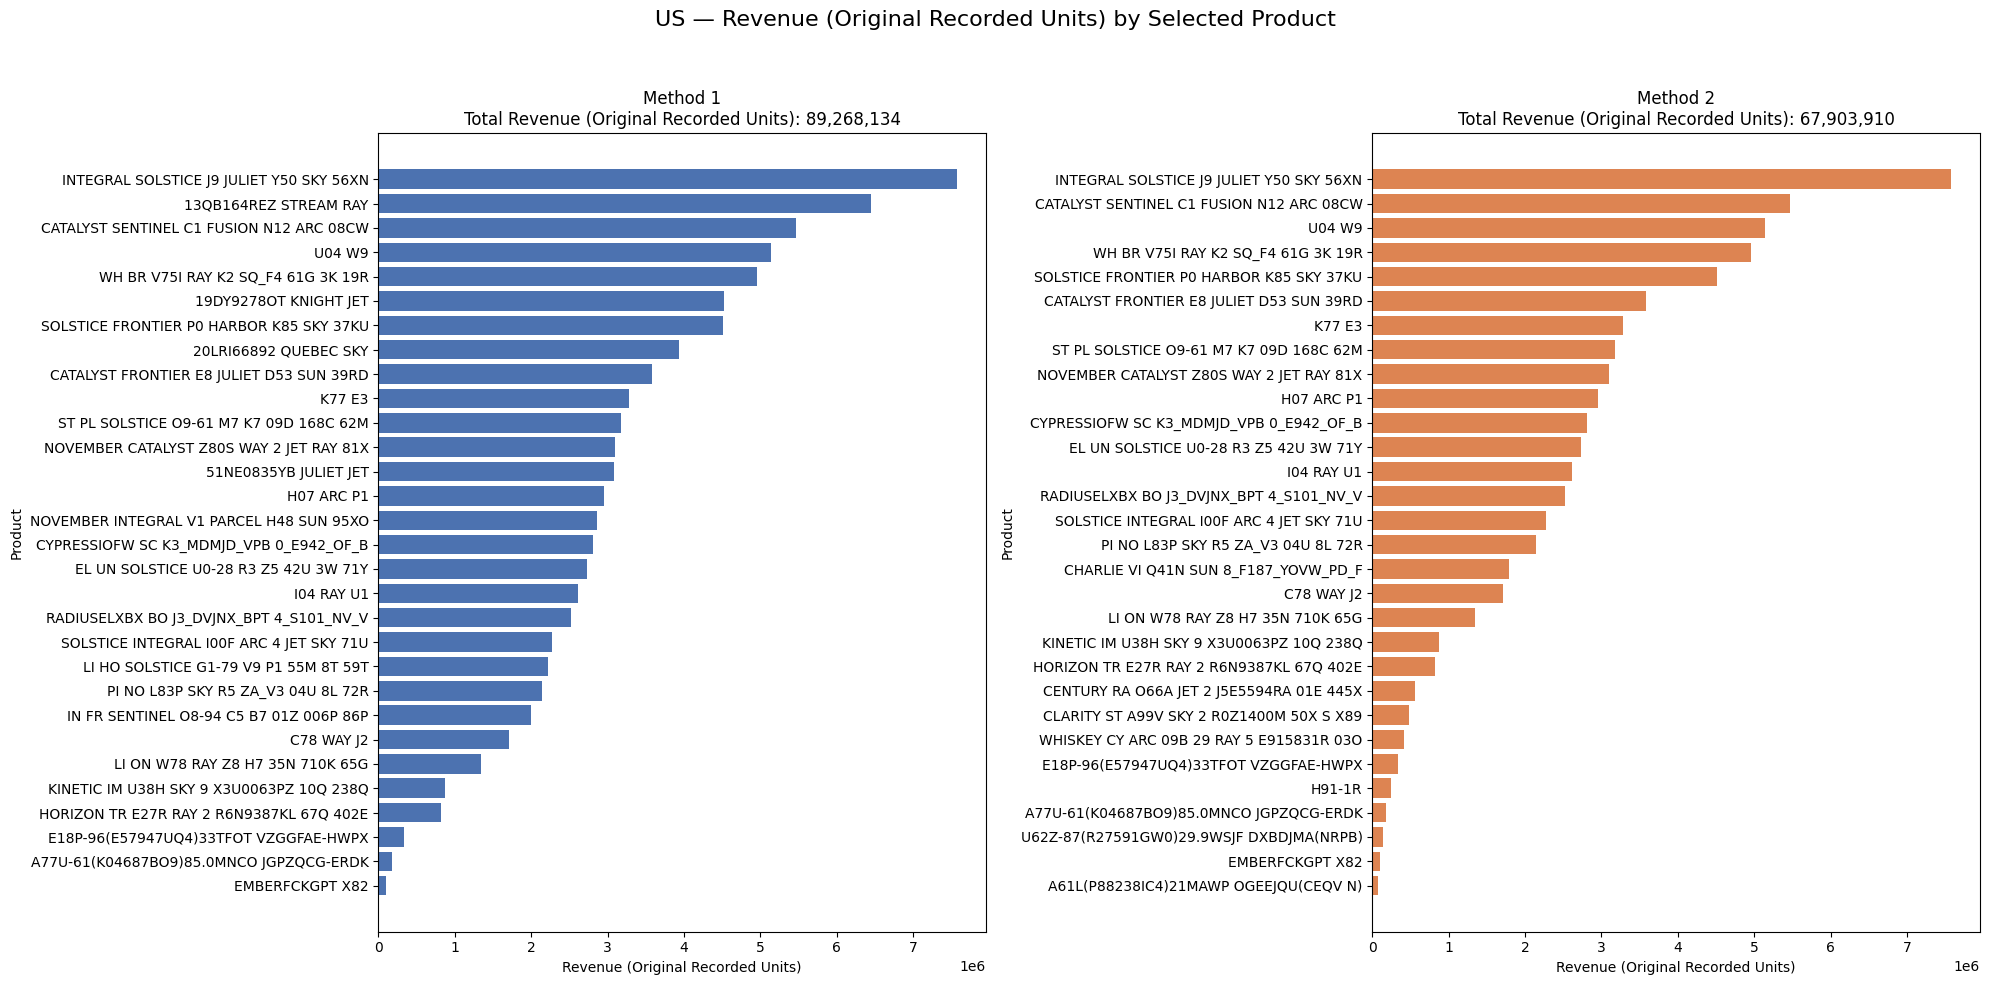

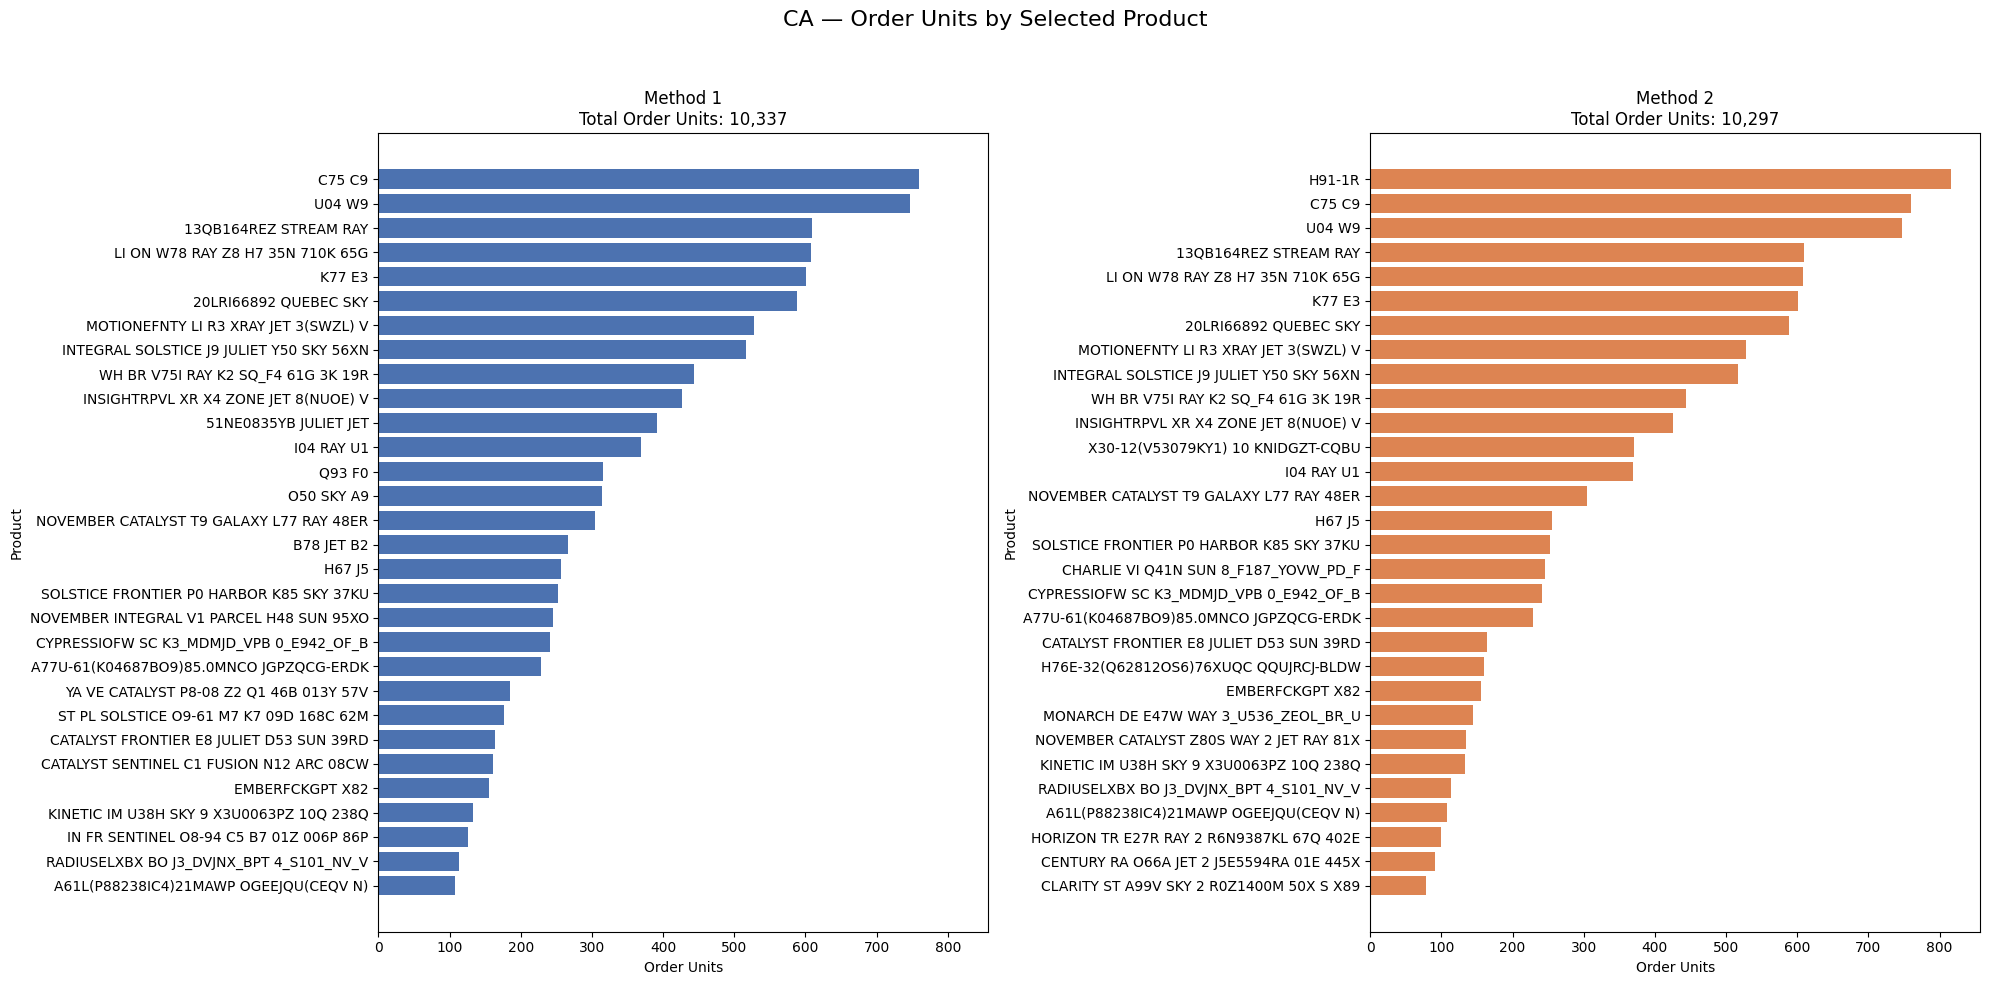

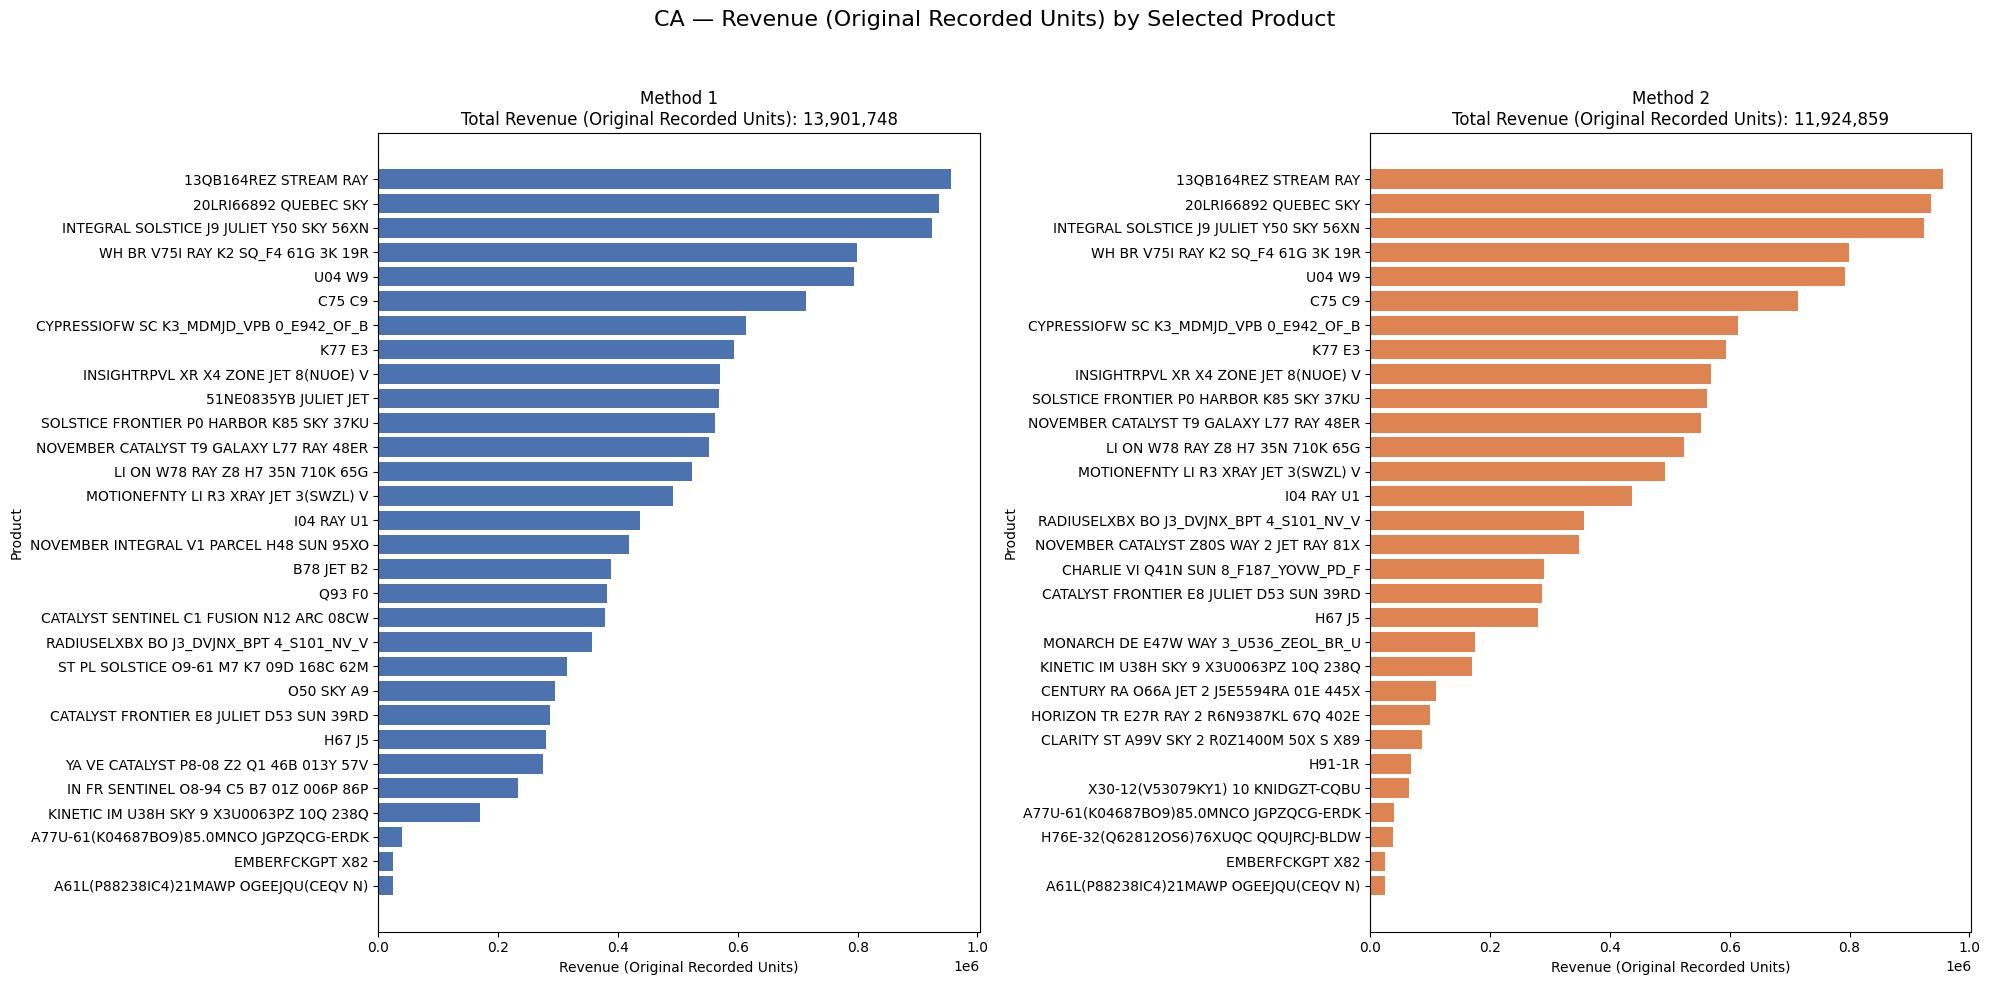

In [13]:
def plot_method_comparison(country, method1, method2, metric, label):
    fig, axes = plt.subplots(1, 2, figsize=(20, 10), sharex=True)

    comparisons = [
        ("Method 1", method1, "#4C72B0"),
        ("Method 2", method2, "#DD8452"),
    ]

    max_value = max(method1[metric].max(), method2[metric].max())

    for ax, (method_name, summary, color) in zip(axes, comparisons):
        plot_df = summary.sort_values(metric, ascending=True)
        positions = np.arange(len(plot_df))

        ax.barh(positions, plot_df[metric], color=color)
        ax.set_yticks(positions)
        ax.set_yticklabels(plot_df["product_name"])
        ax.set_title(f"{method_name}\nTotal {label}: {plot_df[metric].sum():,.0f}")
        ax.set_xlabel(label)
        ax.set_ylabel("Product")
        ax.set_xlim(0, max_value * 1.05)

    fig.suptitle(f"{country} — {label} by Selected Product", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


for country in ["US", "CA"]:
    result = country_results[country]
    method1 = result["method1_top30_products"]
    method2 = result["method2_top6_each_family"]

    if method1.empty or method2.empty:
        print(f"{country}: insufficient candidates for method comparison.")
        continue

    plot_method_comparison(
        country,
        method1,
        method2,
        metric="order_units",
        label="Order Units",
    )

    plot_method_comparison(
        country,
        method1,
        method2,
        metric="revenue",
        label="Revenue (Original Recorded Units)",
    )

# Method 1 is selected for both countries because its selected products
# have higher total recent revenue and order units than Method 2.
# Subsequent pricing analysis uses each country's Method 1 Top30 products.

Based on the comparison above, we select Method 1 for both countries because the products selected have higher revenue and order units.

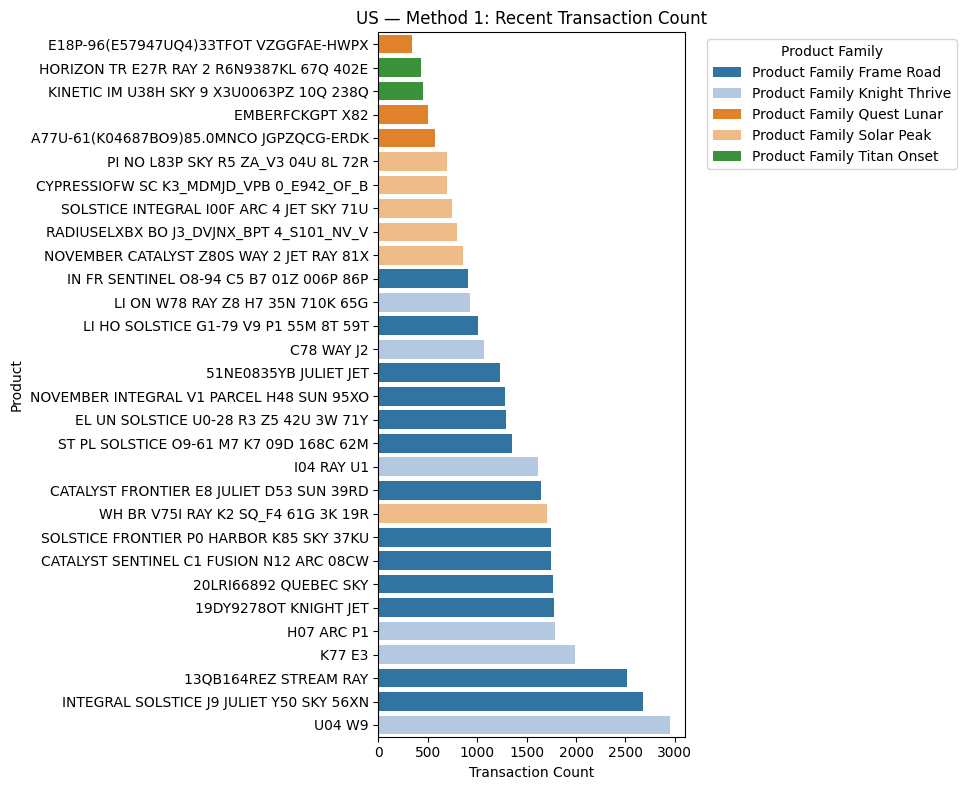

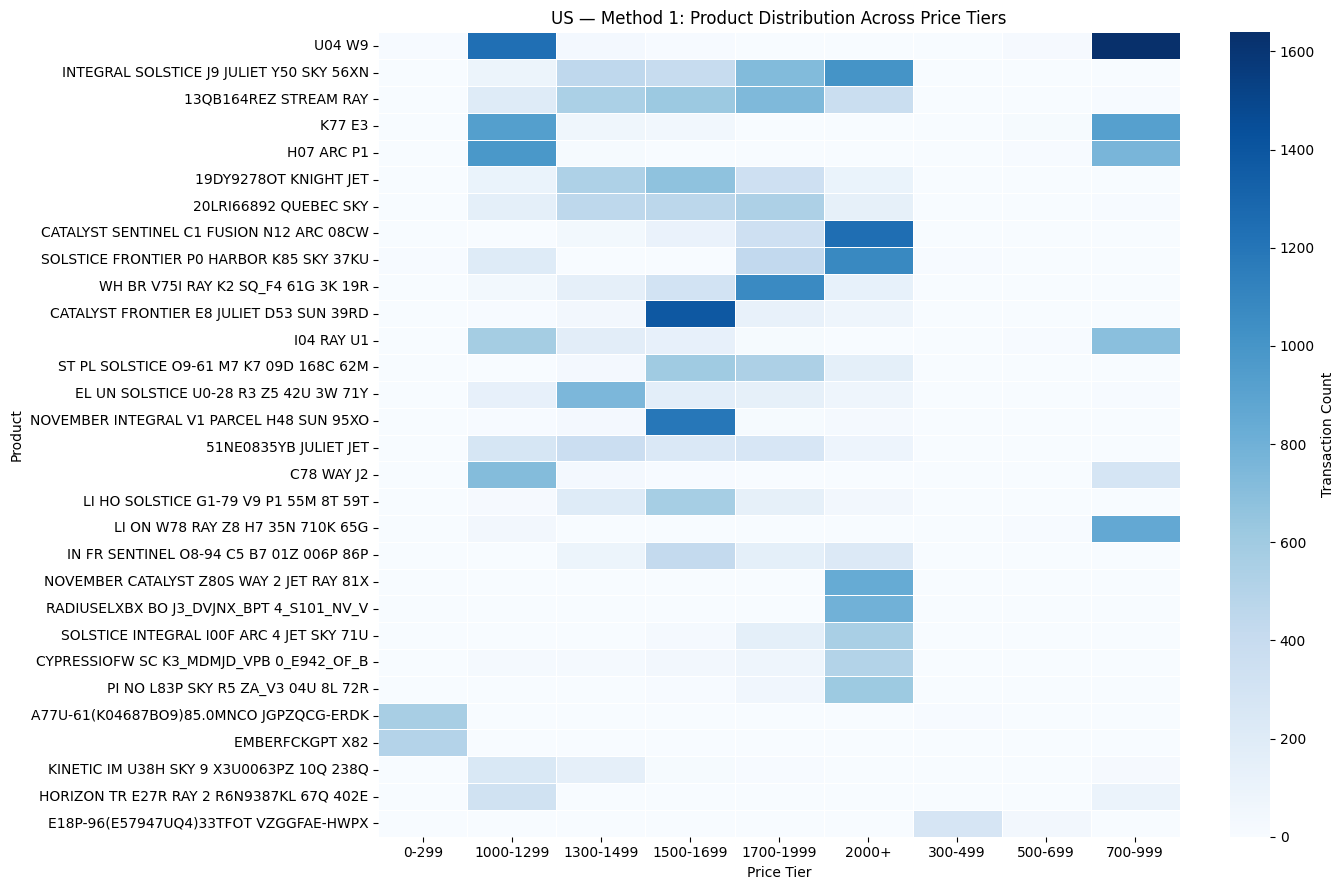

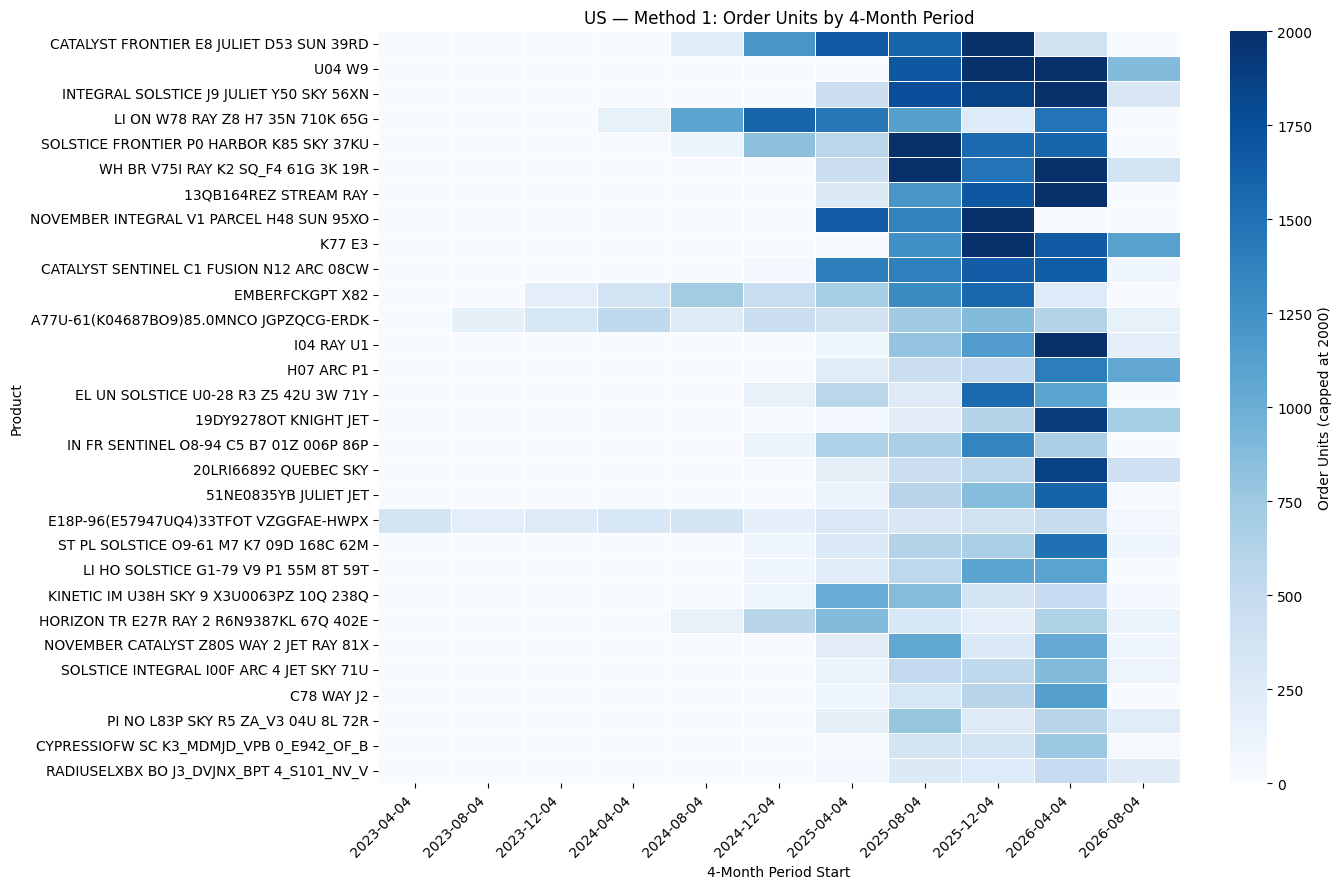

In [22]:
# US — Method 1
us_products = country_results["US"]["method1_top30_products"]

us_core = country_core_data["US"]

us_selected_recent = us_core[
    us_core["pricing_date"].ge(six_month_start)
    & us_core["product_name"].isin(us_products["product_name"])
].copy()

us_family_order = sorted(us_products["product_family"].dropna().unique())
us_family_palette = dict(
    zip(
        us_family_order,
        sns.color_palette("tab20", n_colors=len(us_family_order)),
    )
)

plot_transaction_count_bars(
    us_products,
    "US — Method 1",
    us_family_palette,
    us_family_order,
)

plot_price_tier_heatmap(
    us_selected_recent,
    "US — Method 1",
)

us_period_summary = check_product_period_coverage(
    us_core,
    us_products["product_name"],
)

plot_period_units_heatmap(
    us_period_summary,
    "US — Method 1",
)

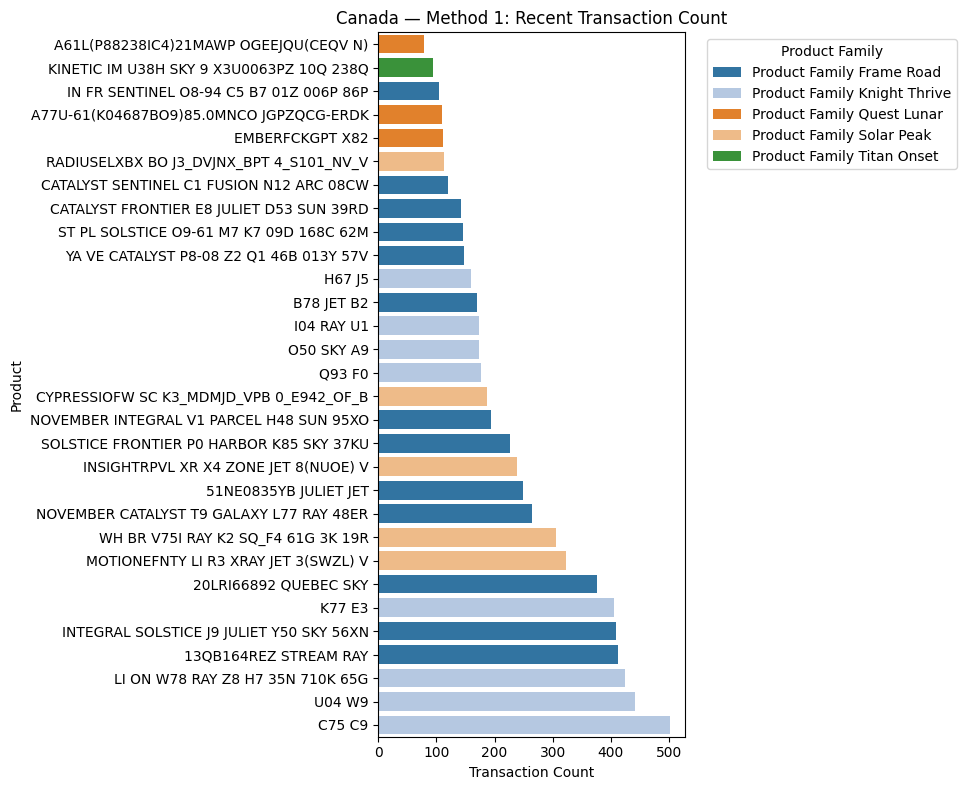

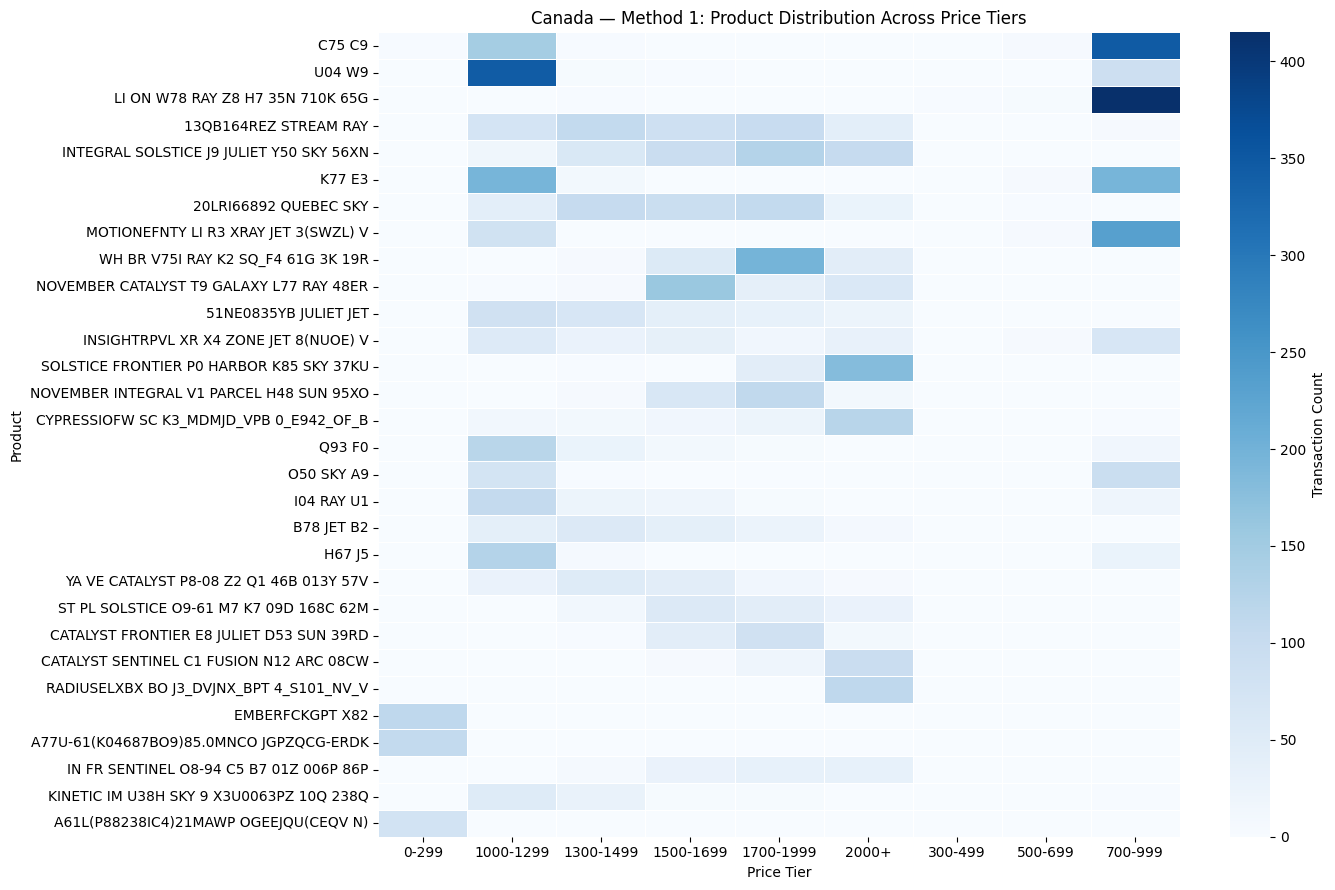

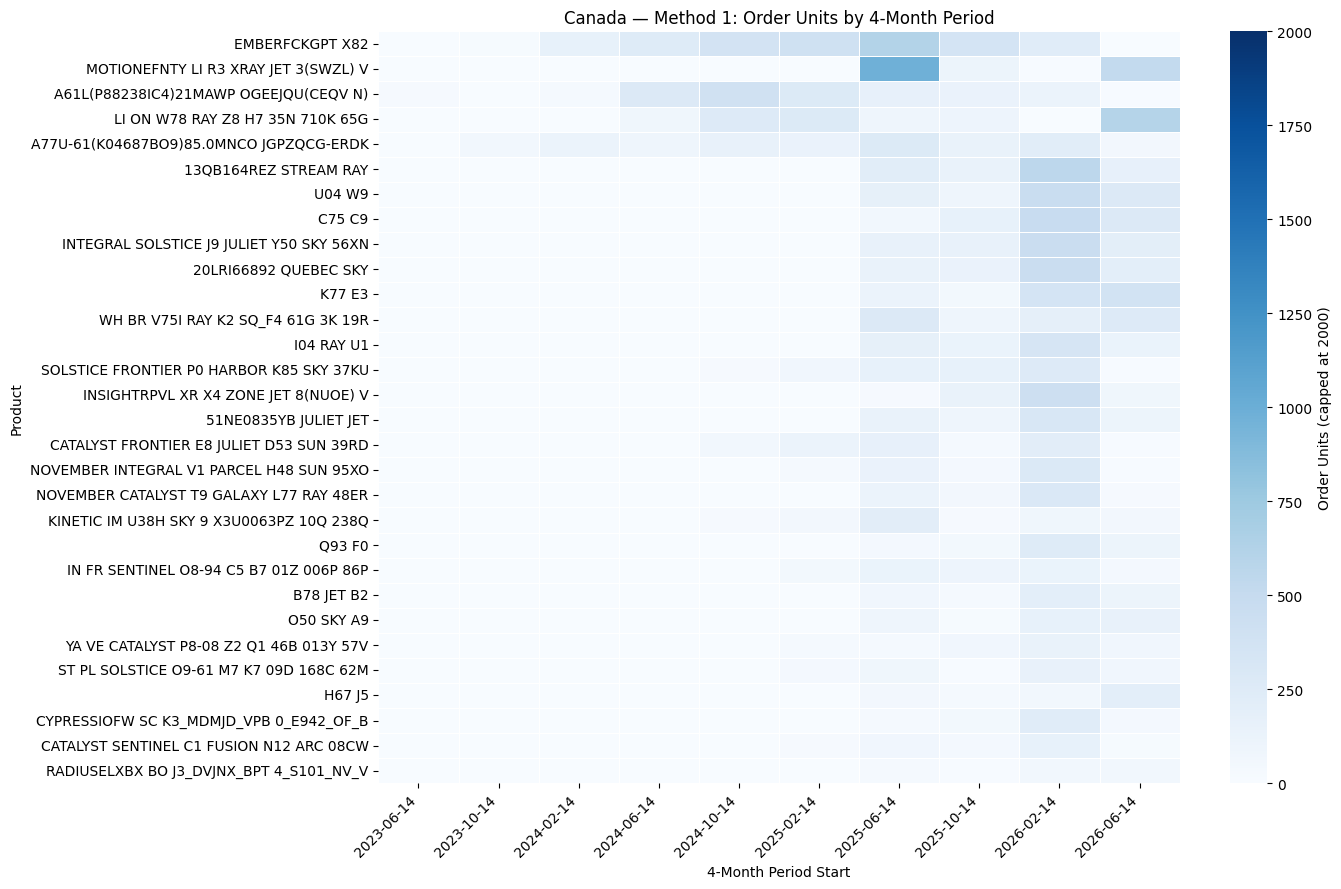

In [23]:
# Canada — Method 1
ca_products = country_results["CA"]["method1_top30_products"]

ca_core = country_core_data["CA"]

ca_selected_recent = ca_core[
    ca_core["pricing_date"].ge(six_month_start)
    & ca_core["product_name"].isin(ca_products["product_name"])
].copy()

ca_family_order = sorted(ca_products["product_family"].dropna().unique())
ca_family_palette = dict(
    zip(
        ca_family_order,
        sns.color_palette("tab20", n_colors=len(ca_family_order)),
    )
)

plot_transaction_count_bars(
    ca_products,
    "Canada — Method 1",
    ca_family_palette,
    ca_family_order,
)

plot_price_tier_heatmap(
    ca_selected_recent,
    "Canada — Method 1",
)

ca_period_summary = check_product_period_coverage(
    ca_core,
    ca_products["product_name"],
)

plot_period_units_heatmap(
    ca_period_summary,
    "Canada — Method 1",
)

### 8. Export Selected Product Transactions
Export cleaned transaction-level data for the selected products in each country, using Method 1 for both the US and Canada. Each file includes the full available history for subsequent pricing analysis.

In [16]:
# Export full-history transactions for each country's selected products
output_dir = project_dir / "pricing_eda_outputs"
output_dir.mkdir(parents=True, exist_ok=True)

country_methods = {
    "US": "method1_top30_products",
    "CA": "method1_top30_products",
}

for country, method_key in country_methods.items():
    selected_products = country_results[country][method_key]

    # Match the same product grouping keys used during selection
    product_keys = ["product_name", "product_family", "product_type"]
    selected_keys = selected_products[product_keys].drop_duplicates()

    country_transactions = country_core_data[country]

    export_data = country_transactions.merge(
        selected_keys,
        on=product_keys,
        how="inner",
        validate="many_to_one",
    )

    file_path = output_dir / f"{country}_selected_top30_transactions.csv"
    export_data.to_csv(file_path, index=False)

    print(
        f"{country}: exported {len(export_data):,} transaction rows "
        f"for {len(selected_keys)} selected product groups."
    )
    print(f"Saved to: {file_path}")

US: exported 95,003 transaction rows for 30 selected product groups.
Saved to: /Users/AustinZhang/Desktop/Capstone/pricing_eda_outputs/US_selected_top30_transactions.csv
CA: exported 16,719 transaction rows for 30 selected product groups.
Saved to: /Users/AustinZhang/Desktop/Capstone/pricing_eda_outputs/CA_selected_top30_transactions.csv
